In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load cleaned dataset
df = pd.read_csv("../data/cleaned_nyc311.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTop 10 Problem Categories:")
print(df["complaint_type"].value_counts().head(10))

Dataset Shape: (30000, 49)

Columns:
['unique_key', 'created_date', 'closed_date', 'agency', 'agency_name', 'complaint_type', 'descriptor', 'location_type', 'incident_zip', 'incident_address', 'street_name', 'cross_street_1', 'cross_street_2', 'intersection_street_1', 'intersection_street_2', 'address_type', 'city', 'landmark', 'status', 'resolution_description', 'resolution_action_updated_date', 'community_board', 'council_district', 'police_precinct', 'bbl', 'borough', 'x_coordinate_state_plane', 'y_coordinate_state_plane', 'open_data_channel_type', 'park_facility_name', 'park_borough', 'latitude', 'longitude', 'location', 'descriptor_2', 'vehicle_type', 'taxi_pick_up_location', 'facility_type', 'due_date', 'bridge_highway_name', 'bridge_highway_direction', 'road_ramp', 'bridge_highway_segment', 'taxi_company_borough', 'year', 'month', 'day_of_week', 'hour', 'report_text']

Top 10 Problem Categories:
complaint_type
Noise - Residential        5377
Illegal Parking            4820
HEAT/

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned_nyc311.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTop 10 Problem Categories:")
print(df["complaint_type"].value_counts().head(10))

Dataset Shape: (30000, 49)

Columns:
['unique_key', 'created_date', 'closed_date', 'agency', 'agency_name', 'complaint_type', 'descriptor', 'location_type', 'incident_zip', 'incident_address', 'street_name', 'cross_street_1', 'cross_street_2', 'intersection_street_1', 'intersection_street_2', 'address_type', 'city', 'landmark', 'status', 'resolution_description', 'resolution_action_updated_date', 'community_board', 'council_district', 'police_precinct', 'bbl', 'borough', 'x_coordinate_state_plane', 'y_coordinate_state_plane', 'open_data_channel_type', 'park_facility_name', 'park_borough', 'latitude', 'longitude', 'location', 'descriptor_2', 'vehicle_type', 'taxi_pick_up_location', 'facility_type', 'due_date', 'bridge_highway_name', 'bridge_highway_direction', 'road_ramp', 'bridge_highway_segment', 'taxi_company_borough', 'year', 'month', 'day_of_week', 'hour', 'report_text']

Top 10 Problem Categories:
complaint_type
Noise - Residential        5377
Illegal Parking            4820
HEAT/

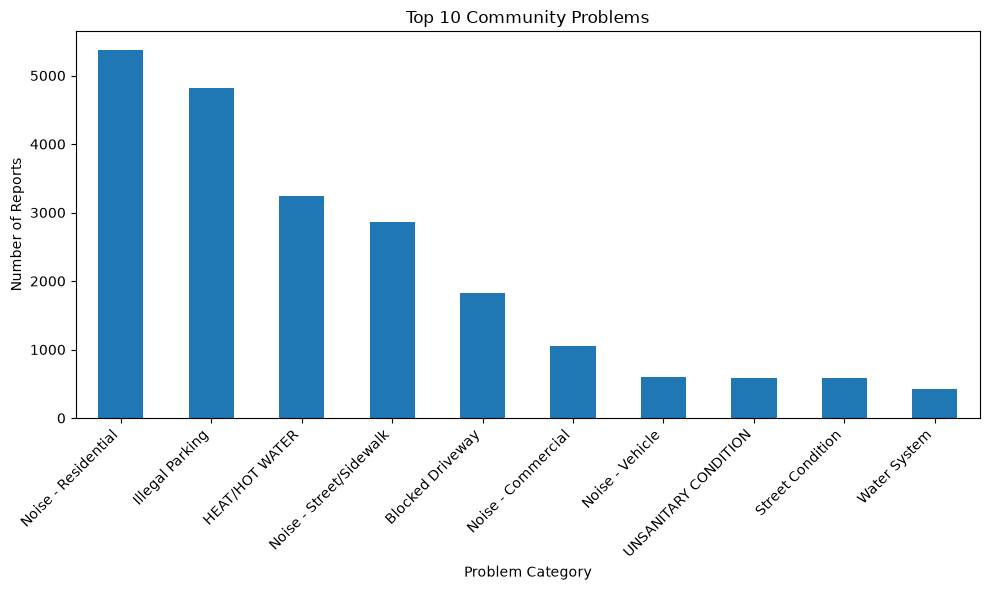

In [7]:
top10 = df["complaint_type"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top10.plot(kind="bar")

plt.title("Top 10 Community Problems")
plt.xlabel("Problem Category")
plt.ylabel("Number of Reports")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [4]:
monthly_reports = df.groupby(["year", "month"]).size()
print(monthly_reports)

year  month
2025  10       3000
      11       3000
      12       3000
2026  1        3000
      2        3000
      3        3000
      4        3000
      5        3000
      6        3000
      7        3000
dtype: int64


In [5]:
df = pd.read_csv("../data/cleaned_nyc311.csv")

In [6]:
monthly_reports = df.groupby(["year", "month"]).size()

print(monthly_reports)

year  month
2025  10       3000
      11       3000
      12       3000
2026  1        3000
      2        3000
      3        3000
      4        3000
      5        3000
      6        3000
      7        3000
dtype: int64


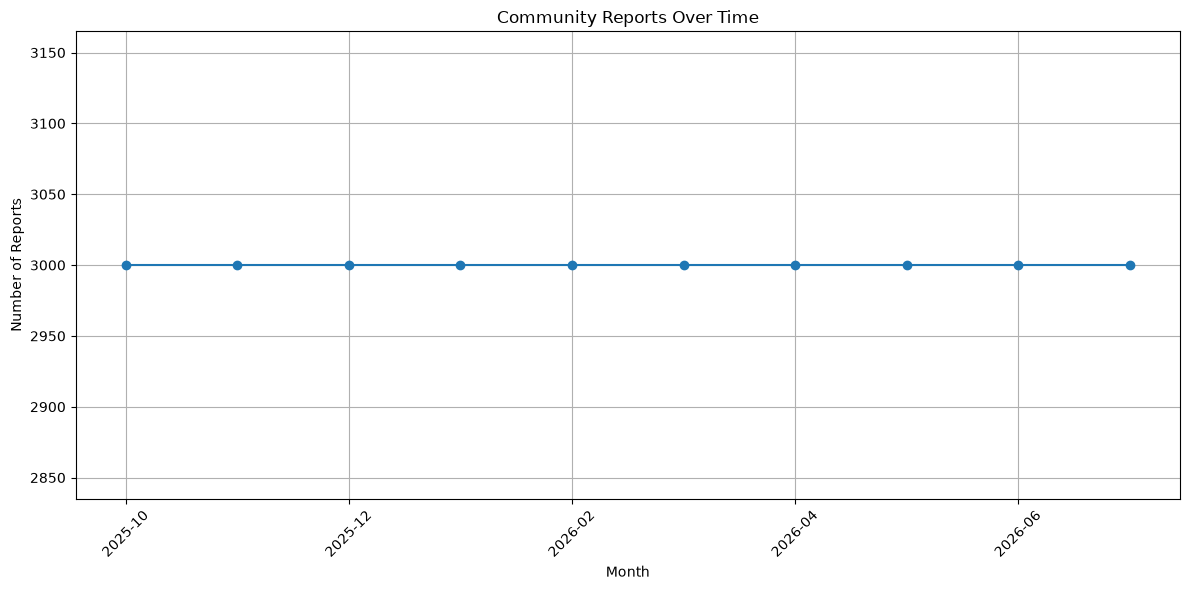

In [7]:
monthly_reports = df.groupby(
    ["year", "month"]
).size()

monthly_reports.index = [
    f"{year}-{month:02d}"
    for year, month in monthly_reports.index
]

plt.figure(figsize=(12, 6))

monthly_reports.plot(kind="line", marker="o")

plt.title("Community Reports Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Reports")
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
# Monthly reports by problem category

monthly_category = df.groupby(
    ["year", "month", "complaint_type"]
).size()

print(monthly_category.head(20))

year  month  complaint_type                 
2025  10     APPLIANCE                            4
             Abandoned Bike                       2
             Abandoned Vehicle                   10
             Air Quality                          1
             Animal in a Park                     1
             Animal-Abuse                        10
             Blocked Driveway                   191
             Building/Use                        17
             Construction Safety Enforcement     32
             Consumer Complaint                   8
             Curb Condition                       4
             DOOR/WINDOW                         18
             Damaged Tree                        48
             Dead Animal                          6
             Dead/Dying Tree                      7
             Derelict Vehicles                   11
             Dirty Condition                     16
             Drinking                             7
             Drug A

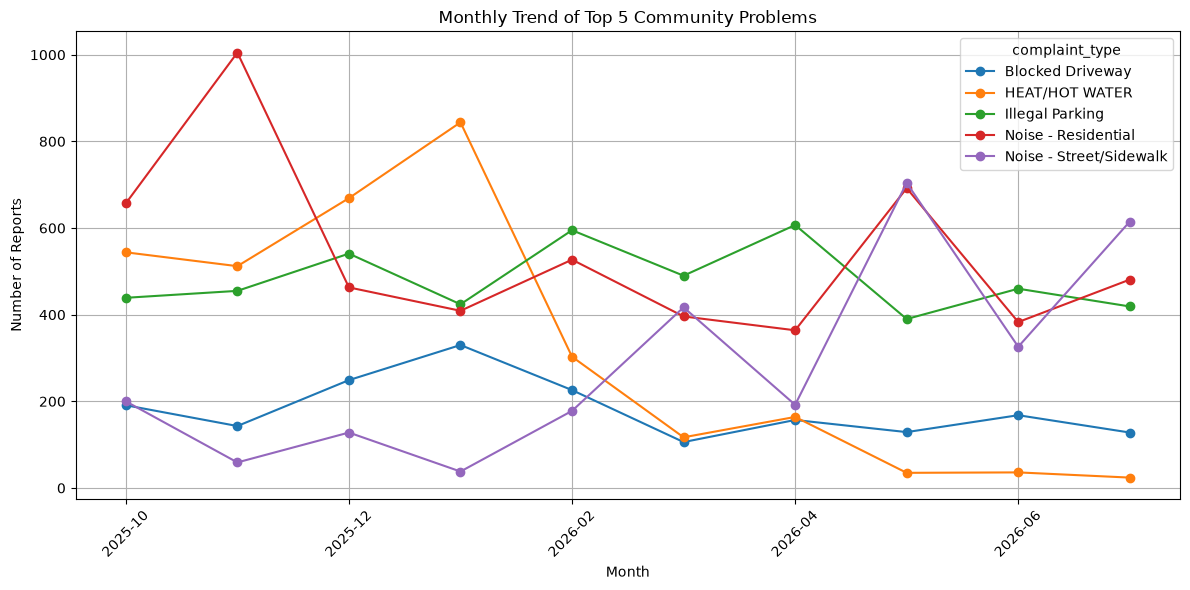

In [8]:
# Monthly trend of top problem categories

top_categories = df["complaint_type"].value_counts().head(5).index

trend_data = df[
    df["complaint_type"].isin(top_categories)
].groupby(
    ["year", "month", "complaint_type"]
).size().unstack(fill_value=0)

trend_data.index = [
    f"{year}-{month:02d}"
    for year, month in trend_data.index
]

trend_data.plot(
    kind="line",
    figsize=(12, 6),
    marker="o"
)

plt.title("Monthly Trend of Top 5 Community Problems")
plt.xlabel("Month")
plt.ylabel("Number of Reports")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
# Top 10 problem categories

top_10 = df["complaint_type"].value_counts().head(10)

print(top_10)

complaint_type
Noise - Residential        5377
Illegal Parking            4820
HEAT/HOT WATER             3248
Noise - Street/Sidewalk    2857
Blocked Driveway           1827
Noise - Commercial         1053
Noise - Vehicle             596
UNSANITARY CONDITION        589
Street Condition            582
Water System                426
Name: count, dtype: int64


In [16]:
# Check missing values

missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

print(missing_values.head(15))

taxi_company_borough        29973
facility_type               29953
due_date                    29936
bridge_highway_direction    29932
road_ramp                   29932
bridge_highway_segment      29892
bridge_highway_name         29889
taxi_pick_up_location       29678
vehicle_type                28658
descriptor_2                20741
landmark                     9651
intersection_street_1        7826
intersection_street_2        7822
cross_street_1               7076
cross_street_2               7075
dtype: int64


In [15]:
# Check data types

print(df.dtypes)

unique_key                          int64
created_date                          str
closed_date                           str
agency                                str
agency_name                           str
complaint_type                        str
descriptor                            str
location_type                         str
incident_zip                      float64
incident_address                      str
street_name                           str
cross_street_1                        str
cross_street_2                        str
intersection_street_1                 str
intersection_street_2                 str
address_type                          str
city                                  str
landmark                              str
status                                str
resolution_description                str
resolution_action_updated_date        str
community_board                       str
council_district                  float64
police_precinct                   

In [10]:
# Prepare text data for ML

X = df["descriptor"].fillna("Unknown")
y = df["complaint_type"]

print("Input text:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nNumber of classes:", y.nunique())

Input text:
0    Loud Music/Party
1    Banging/Pounding
2         Food Vendor
3        Loud Talking
4    Banging/Pounding
Name: descriptor, dtype: str

Target:
0    Noise - Residential
1    Noise - Residential
2     Vendor Enforcement
3    Noise - Residential
4    Noise - Residential
Name: complaint_type, dtype: str

Number of classes: 144


In [11]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert text into numerical features
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000
)

X_tfidf = tfidf.fit_transform(X)

print("Original text samples:", len(X))
print("TF-IDF shape:", X_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

Original text samples: 30000
TF-IDF shape: (30000, 757)
Number of features: 757


In [12]:
# Check categories with very few reports

category_counts = y.value_counts()

print("Total categories:", len(category_counts))

print("\nCategories with fewer than 5 reports:")
print(category_counts[category_counts < 5])

Total categories: 144

Categories with fewer than 5 reports:
complaint_type
Investigations and Discipline (IAD)     4
Industrial Waste                        4
Bridge Condition                        4
Dumpster Complaint                      4
Illegal Animal Kept as Pet              3
For Hire Vehicle Report                 3
New Tree Request                        3
Water Quality                           3
OUTSIDE BUILDING                        3
Hazardous Material                      3
Ferry Inquiry                           2
Found Property                          2
Bike Rack                               2
Disorderly Youth                        2
Ferry Complaint                         2
Plant                                   2
Poison Ivy                              2
Mold                                    1
Special Natural Area District (SNAD)    1
Taxi Compliment                         1
School Maintenance                      1
Uprooted Stump                          1


In [19]:
# Keep categories with at least 5 reports

valid_categories = category_counts[category_counts >= 5].index

mask = y.isin(valid_categories).to_numpy()

X_tfidf_filtered = X_tfidf[mask]
y_filtered = y[mask]

print("Original samples:", len(y))
print("Filtered samples:", len(y_filtered))
print("Categories remaining:", y_filtered.nunique())

Original samples: 30000
Filtered samples: 29938
Categories remaining: 113


In [20]:
from sklearn.model_selection import train_test_split

# Split filtered data
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf_filtered,
    y_filtered,
    test_size=0.2,
    random_state=42,
    stratify=y_filtered
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 23950
Testing samples: 5988


In [21]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(
    max_iter=1000
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [22]:
# Make predictions on the test data

y_pred = model.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed!
First 10 predictions:
['Construction Safety Enforcement' 'HEAT/HOT WATER' 'HEAT/HOT WATER'
 'Noise - Residential' 'Illegal Parking' 'Illegal Parking'
 'Noise - Vehicle' 'Illegal Dumping' 'Illegal Parking'
 'Noise - Residential']


In [23]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.8398463593854375
Accuracy Percentage: 83.98 %

Classification Report:
                                         precision    recall  f1-score   support

                              APPLIANCE       1.00      1.00      1.00        17
                         Abandoned Bike       1.00      1.00      1.00         3
                      Abandoned Vehicle       1.00      1.00      1.00        71
                            Air Quality       0.80      0.89      0.84         9
                       Animal in a Park       1.00      0.80      0.89         5
                           Animal-Abuse       1.00      0.69      0.81        16
                               Asbestos       1.00      1.00      1.00         1
                      Bike/Roller/Skate       0.00      0.00      0.00         3
                       Blocked Driveway       1.00      1.00      1.00       365
                                Boilers       1.00      1.00      1.00         5
                   B

In [24]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix Shape:", cm.shape)

Confusion Matrix Shape: (113, 113)


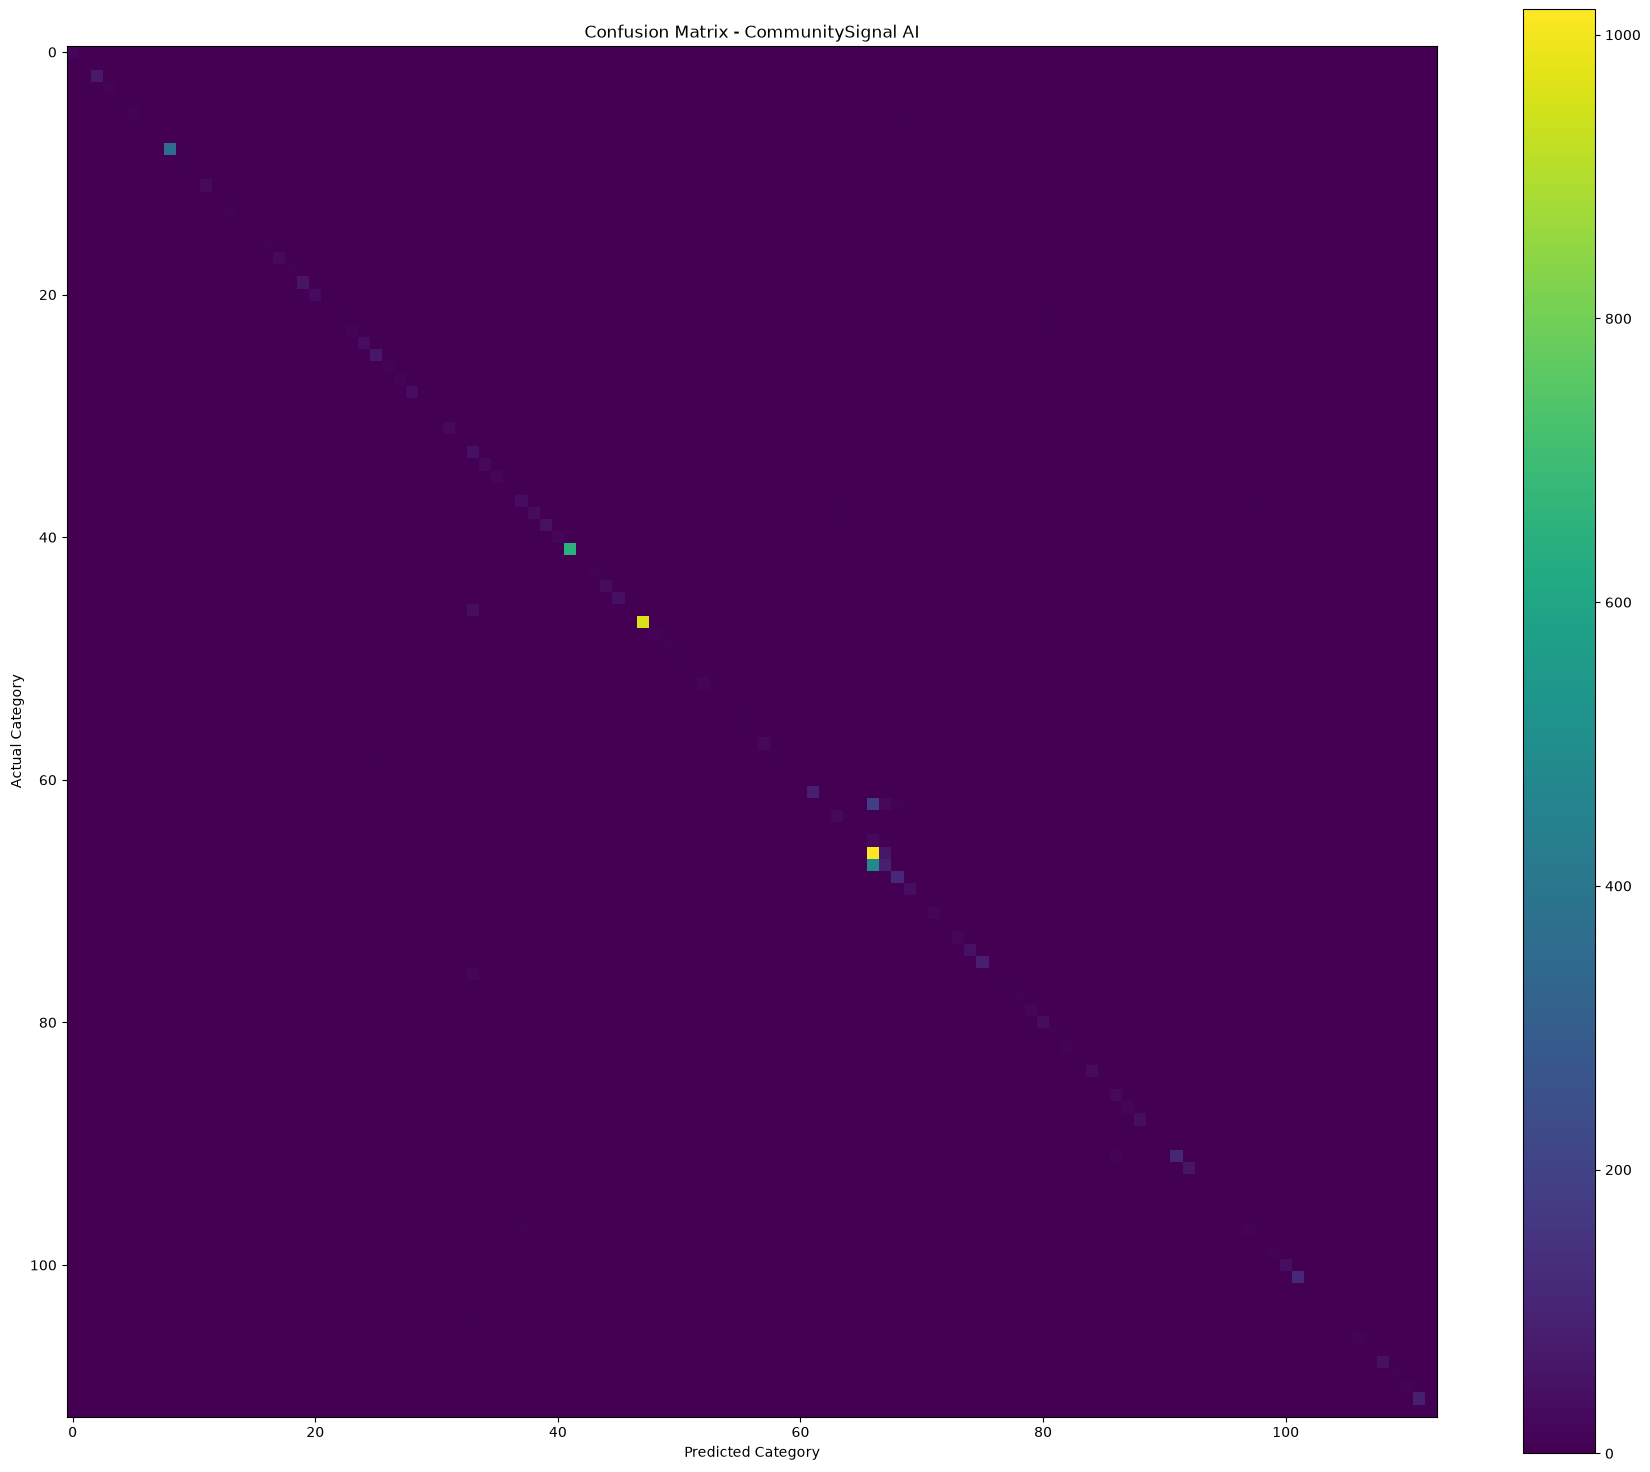

In [25]:
# Visualize the confusion matrix

plt.figure(figsize=(18, 15))

plt.imshow(cm, interpolation="nearest")

plt.title("Confusion Matrix - CommunitySignal AI")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.colorbar()

plt.tight_layout()
plt.show()

In [26]:
# Test CommunitySignal AI with a new report

new_report = ["loud music and people shouting at night"]

new_report_tfidf = tfidf.transform(new_report)

prediction = model.predict(new_report_tfidf)

print("New Report:", new_report[0])
print("Predicted Problem:", prediction[0])

New Report: loud music and people shouting at night
Predicted Problem: Noise - Residential


In [27]:
from sklearn.metrics.pairwise import cosine_similarity

# Compare the new report with all existing reports
similarity_scores = cosine_similarity(
    new_report_tfidf,
    X_tfidf
)

print("Similarity matrix shape:", similarity_scores.shape)

Similarity matrix shape: (1, 30000)


In [28]:
# Test report

new_report = ["loud music and people shouting at night"]

new_report_tfidf = tfidf.transform(new_report)

print("New report converted successfully!")
print("TF-IDF shape:", new_report_tfidf.shape)

New report converted successfully!
TF-IDF shape: (1, 757)


In [29]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_scores = cosine_similarity(
    new_report_tfidf,
    X_tfidf
)

print("Similarity calculation completed!")
print("Similarity matrix shape:", similarity_scores.shape)

Similarity calculation completed!
Similarity matrix shape: (1, 30000)


In [30]:
import numpy as np

top_5_indices = np.argsort(similarity_scores[0])[-5:][::-1]

print("Top 5 Similar Reports:\n")

for i, index in enumerate(top_5_indices, start=1):
    print(f"{i}. Similarity Score: {similarity_scores[0][index]:.4f}")
    print(f"   Report: {df.iloc[index]['report_text']}")
    print(f"   Category: {df.iloc[index]['complaint_type']}")
    print()

Top 5 Similar Reports:

1. Similarity Score: 0.8066
   Report: noise - residential loud music/party
   Category: Noise - Residential

2. Similarity Score: 0.8066
   Report: noise - commercial loud music/party
   Category: Noise - Commercial

3. Similarity Score: 0.8066
   Report: noise - residential loud music/party
   Category: Noise - Residential

4. Similarity Score: 0.8066
   Report: noise - residential loud music/party
   Category: Noise - Residential

5. Similarity Score: 0.8066
   Report: noise - street/sidewalk loud music/party
   Category: Noise - Street/Sidewalk



In [31]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_tfidf)

print("K-Means clustering completed!")
print("Number of clusters:", len(set(clusters)))

K-Means clustering completed!
Number of clusters: 10


In [32]:
df["cluster"] = clusters

print("Cluster distribution:")
print(df["cluster"].value_counts().sort_index())

Cluster distribution:
cluster
0     1827
1     6866
2      848
3     2304
4     1645
5      823
6    13986
7      530
8      516
9      655
Name: count, dtype: int64


In [34]:
for cluster in sorted(df["cluster"].unique()):
    print("\n" + "=" * 60)
    print("CLUSTER", cluster)
    print("=" * 60)

    cluster_reports = df[df["cluster"] == cluster]["report_text"].head(5)

    for report in cluster_reports:
        print("-", report)


CLUSTER 0
- blocked driveway no access
- blocked driveway no access
- blocked driveway no access
- blocked driveway no access
- blocked driveway partial access

CLUSTER 1
- noise - residential loud music/party
- noise - residential loud music/party
- noise - commercial loud music/party
- noise - residential loud music/party
- noise - street/sidewalk loud music/party

CLUSTER 2
- illegal parking posted parking sign violation
- illegal parking posted parking sign violation
- illegal parking posted parking sign violation
- illegal parking posted parking sign violation
- illegal parking posted parking sign violation

CLUSTER 3
- heat/hot water entire building
- heat/hot water entire building
- heat/hot water entire building
- heat/hot water entire building
- heat/hot water entire building

CLUSTER 4
- noise - residential banging/pounding
- noise - residential banging/pounding
- noise - residential banging/pounding
- noise - residential banging/pounding
- noise - residential banging/poundi

In [35]:
print("Latitude missing:", df["latitude"].isna().sum())
print("Longitude missing:", df["longitude"].isna().sum())

print("\nTotal reports:", len(df))

Latitude missing: 478
Longitude missing: 478

Total reports: 30000


In [36]:
geo_df = df.dropna(subset=["latitude", "longitude"]).copy()

print("Reports with location:", len(geo_df))
print("Reports removed:", len(df) - len(geo_df))

print("\nLocation sample:")
print(geo_df[["latitude", "longitude"]].head())

Reports with location: 29522
Reports removed: 478

Location sample:
    latitude  longitude
0  40.889687 -73.834823
1  40.577620 -73.990378
2  40.720113 -73.993387
3  40.803040 -73.965859
4  40.584498 -73.972480


In [37]:
from sklearn.cluster import DBSCAN

coordinates = geo_df[["latitude", "longitude"]]

dbscan = DBSCAN(
    eps=0.005,
    min_samples=10
)

geo_df["geo_cluster"] = dbscan.fit_predict(coordinates)

print("DBSCAN completed!")
print("Number of geographic clusters:",
      geo_df["geo_cluster"].nunique() - (1 if -1 in geo_df["geo_cluster"].values else 0))

print("Noise/outlier reports:",
      (geo_df["geo_cluster"] == -1).sum())


DBSCAN completed!
Number of geographic clusters: 47
Noise/outlier reports: 519


In [38]:
print("Geographic Cluster Distribution:")
print(geo_df["geo_cluster"].value_counts().sort_index())

Geographic Cluster Distribution:
geo_cluster
-1       519
 0     27508
 1        32
 2        36
 3        75
 4       146
 5        84
 6       244
 7        36
 8        32
 9        28
 10       49
 11       18
 12       44
 13       39
 14       19
 15       19
 16       47
 17       19
 18       11
 19       14
 20       39
 21       20
 22       42
 23       11
 24       28
 25       17
 26       60
 27       52
 28       19
 29       15
 30       15
 31       13
 32       15
 33       10
 34       17
 35        8
 36        4
 37       13
 38       10
 39       10
 40       23
 41        6
 42        9
 43        8
 44       23
 45        8
 46        8
Name: count, dtype: int64


In [39]:
print("Geographic Cluster Distribution:")
print(geo_df["geo_cluster"].value_counts().sort_index())

Geographic Cluster Distribution:
geo_cluster
-1       519
 0     27508
 1        32
 2        36
 3        75
 4       146
 5        84
 6       244
 7        36
 8        32
 9        28
 10       49
 11       18
 12       44
 13       39
 14       19
 15       19
 16       47
 17       19
 18       11
 19       14
 20       39
 21       20
 22       42
 23       11
 24       28
 25       17
 26       60
 27       52
 28       19
 29       15
 30       15
 31       13
 32       15
 33       10
 34       17
 35        8
 36        4
 37       13
 38       10
 39       10
 40       23
 41        6
 42        9
 43        8
 44       23
 45        8
 46        8
Name: count, dtype: int64


In [40]:
dbscan = DBSCAN(
    eps=0.001,
    min_samples=10
)

geo_df["geo_cluster"] = dbscan.fit_predict(
    geo_df[["latitude", "longitude"]]
)

print("DBSCAN completed!")

print(
    "Number of geographic clusters:",
    geo_df["geo_cluster"].nunique()
    - (1 if -1 in geo_df["geo_cluster"].values else 0)
)

print(
    "Noise/outlier reports:",
    (geo_df["geo_cluster"] == -1).sum()
)

print("\nLargest geographic clusters:")
print(
    geo_df["geo_cluster"]
    .value_counts()
    .head(10)
)

DBSCAN completed!
Number of geographic clusters: 487
Noise/outlier reports: 18565

Largest geographic clusters:
geo_cluster
-1      18565
 122      634
 66       202
 84       156
 37       126
 14       114
 128      110
 285      103
 129      100
 111       91
Name: count, dtype: int64


In [41]:
dbscan = DBSCAN(
    eps=0.002,
    min_samples=10
)

geo_df["geo_cluster"] = dbscan.fit_predict(
    geo_df[["latitude", "longitude"]]
)

print("DBSCAN completed!")

print(
    "Number of geographic clusters:",
    geo_df["geo_cluster"].nunique()
    - (1 if -1 in geo_df["geo_cluster"].values else 0)
)

print(
    "Noise/outlier reports:",
    (geo_df["geo_cluster"] == -1).sum()
)

print("\nLargest geographic clusters:")
print(
    geo_df["geo_cluster"]
    .value_counts()
    .head(10)
)

DBSCAN completed!
Number of geographic clusters: 335
Noise/outlier reports: 6923

Largest geographic clusters:
geo_cluster
-1     6923
 4     3698
 2     2900
 1     1593
 7     1298
 45     813
 11     636
 30     379
 26     312
 18     310
Name: count, dtype: int64


In [42]:
top_hotspots = (
    geo_df[geo_df["geo_cluster"] != -1]["geo_cluster"]
    .value_counts()
    .head(5)
    .index
)

for cluster in top_hotspots:
    print("\n" + "=" * 60)
    print("HOTSPOT CLUSTER:", cluster)
    print("=" * 60)

    print(
        geo_df[geo_df["geo_cluster"] == cluster]["complaint_type"]
        .value_counts()
        .head(5)
    )


HOTSPOT CLUSTER: 4
complaint_type
Noise - Residential        737
Noise - Street/Sidewalk    730
HEAT/HOT WATER             727
Illegal Parking            276
Noise - Vehicle            120
Name: count, dtype: int64

HOTSPOT CLUSTER: 2
complaint_type
HEAT/HOT WATER             553
Noise - Street/Sidewalk    551
Noise - Residential        450
Noise - Commercial         186
Illegal Parking            185
Name: count, dtype: int64

HOTSPOT CLUSTER: 1
complaint_type
Noise - Residential        278
Noise - Street/Sidewalk    146
Illegal Parking            146
Noise - Commercial         139
HEAT/HOT WATER              97
Name: count, dtype: int64

HOTSPOT CLUSTER: 7
complaint_type
Noise - Residential        223
HEAT/HOT WATER             210
Illegal Parking            151
Noise - Street/Sidewalk    131
Blocked Driveway            57
Name: count, dtype: int64

HOTSPOT CLUSTER: 45
complaint_type
Noise - Residential        649
HEAT/HOT WATER              27
Blocked Driveway            24
Noise -

In [43]:
from sklearn.ensemble import IsolationForest

anomaly_features = df[
    ["hour", "month"]
].copy()

print("Anomaly feature shape:", anomaly_features.shape)
print("\nFeatures being used:")
print(anomaly_features.head())

Anomaly feature shape: (30000, 2)

Features being used:
   hour  month
0    23     10
1    23     10
2    23     10
3    23     10
4    23     10


In [44]:
isolation_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_labels = isolation_model.fit_predict(anomaly_features)

print("Isolation Forest training completed!")
print("\nAnomaly distribution:")
print(pd.Series(anomaly_labels).value_counts())

Isolation Forest training completed!

Anomaly distribution:
 1    28700
-1     1300
Name: count, dtype: int64


In [45]:
df["anomaly_label"] = anomaly_labels

df["anomaly_status"] = df["anomaly_label"].map({
    1: "Normal",
    -1: "Anomaly"
})

print(df[[
    "complaint_type",
    "hour",
    "month",
    "anomaly_status"
]].head(10))

        complaint_type  hour  month anomaly_status
0  Noise - Residential    23     10         Normal
1  Noise - Residential    23     10         Normal
2   Vendor Enforcement    23     10         Normal
3  Noise - Residential    23     10         Normal
4  Noise - Residential    23     10         Normal
5  Noise - Residential    23     10         Normal
6      Illegal Parking    23     10         Normal
7     Blocked Driveway    23     10         Normal
8   Noise - Commercial    23     10         Normal
9       HEAT/HOT WATER    23     10         Normal


In [46]:
anomaly_summary = (
    df[df["anomaly_label"] == -1]
    ["complaint_type"]
    .value_counts()
    .head(10)
)

print("Top 10 problem types among detected anomalies:")
print(anomaly_summary)

Top 10 problem types among detected anomalies:
complaint_type
HEAT/HOT WATER             277
Illegal Parking            209
Noise - Residential        200
Blocked Driveway           103
Noise - Commercial          39
Water System                28
Noise - Street/Sidewalk     27
Snow or Ice                 24
PLUMBING                    20
Street Condition            20
Name: count, dtype: int64


In [47]:
monthly_counts = (
    df.groupby(
        ["year", "month", "complaint_type"]
    )
    .size()
    .reset_index(name="report_count")
)

print("Monthly category data created!")
print(monthly_counts.head(10))

Monthly category data created!
   year  month                   complaint_type  report_count
0  2025     10                        APPLIANCE             4
1  2025     10                   Abandoned Bike             2
2  2025     10                Abandoned Vehicle            10
3  2025     10                      Air Quality             1
4  2025     10                 Animal in a Park             1
5  2025     10                     Animal-Abuse            10
6  2025     10                 Blocked Driveway           191
7  2025     10                     Building/Use            17
8  2025     10  Construction Safety Enforcement            32
9  2025     10               Consumer Complaint             8


In [48]:
monthly_counts = monthly_counts.sort_values(
    ["complaint_type", "year", "month"]
)

monthly_counts["growth_rate"] = (
    monthly_counts
    .groupby("complaint_type")["report_count"]
    .pct_change()
    * 100
)

print("Monthly growth calculated!")
print(
    monthly_counts[
        ["year", "month", "complaint_type", "report_count", "growth_rate"]
    ].head(20)
)

Monthly growth calculated!
     year  month       complaint_type  report_count  growth_rate
745  2026      6  AHV Inspection Unit             1          NaN
0    2025     10            APPLIANCE             4          NaN
90   2025     11            APPLIANCE             8   100.000000
180  2025     12            APPLIANCE             7   -12.500000
268  2026      1            APPLIANCE             9    28.571429
347  2026      2            APPLIANCE            12    33.333333
445  2026      3            APPLIANCE             8   -33.333333
545  2026      4            APPLIANCE            11    37.500000
655  2026      5            APPLIANCE             4   -63.636364
746  2026      6            APPLIANCE            15   275.000000
858  2026      7            APPLIANCE             6   -60.000000
1    2025     10       Abandoned Bike             2          NaN
91   2025     11       Abandoned Bike             3    50.000000
181  2025     12       Abandoned Bike             1   -66.66666

In [49]:
# Get the latest month available for each category
latest_growth = (
    monthly_counts
    .sort_values(["year", "month"])
    .groupby("complaint_type")
    .tail(1)
    .copy()
)

# Remove categories where growth cannot be calculated
latest_growth = latest_growth.dropna(subset=["growth_rate"])

# Show categories with the highest growth
top_emerging = latest_growth.sort_values(
    "growth_rate",
    ascending=False
).head(10)

print("Top Emerging Community Problems:")
print(
    top_emerging[
        ["year", "month", "complaint_type", "report_count", "growth_rate"]
    ]
)

Top Emerging Community Problems:
     year  month       complaint_type  report_count  growth_rate
959  2026      7    Water Maintenance            44  2100.000000
918  2026      7         Noise - Park            28  1300.000000
856  2026      6         Water System           180   718.181818
871  2026      7       Curb Condition             9   350.000000
861  2026      7          Air Quality            12   300.000000
921  2026      7      Noise - Vehicle           124   275.757576
954  2026      7  Urinating in Public             7   250.000000
878  2026      7             Drinking            13   225.000000
960  2026      7  Wood Pile Remaining             3   200.000000
941  2026      7       Standing Water             3   200.000000


In [50]:
# Create a copy for scoring
signal_data = latest_growth.copy()

# Limit extreme growth values
signal_data["growth_capped"] = signal_data["growth_rate"].clip(upper=500)

# Calculate normalized growth score (0-100)
signal_data["growth_score"] = (
    signal_data["growth_capped"] /
    signal_data["growth_capped"].max()
) * 100

# Calculate normalized volume score (0-100)
signal_data["volume_score"] = (
    signal_data["report_count"] /
    signal_data["report_count"].max()
) * 100

# Combine growth and volume
signal_data["signal_score"] = (
    0.5 * signal_data["growth_score"] +
    0.5 * signal_data["volume_score"]
)

# Sort by final signal score
emerging_signals = signal_data.sort_values(
    "signal_score",
    ascending=False
)

print("Emerging Community Signals:")
print(
    emerging_signals[
        [
            "complaint_type",
            "report_count",
            "growth_rate",
            "growth_score",
            "volume_score",
            "signal_score"
        ]
    ].head(10)
)

Emerging Community Signals:
              complaint_type  report_count  growth_rate  growth_score  \
856             Water System           180   718.181818    100.000000   
920  Noise - Street/Sidewalk           615    88.650307     17.730061   
959        Water Maintenance            44  2100.000000    100.000000   
918             Noise - Park            28  1300.000000    100.000000   
919      Noise - Residential           481    25.587467      5.117493   
921          Noise - Vehicle           124   275.757576     55.151515   
871           Curb Condition             9   350.000000     70.000000   
902          Illegal Parking           419    -8.913043     -1.782609   
861              Air Quality            12   300.000000     60.000000   
954      Urinating in Public             7   250.000000     50.000000   

     volume_score  signal_score  
856     29.268293     64.634146  
920    100.000000     58.865031  
959      7.154472     53.577236  
918      4.552846     52.276423 

In [51]:
def get_risk_level(score):
    if score >= 70:
        return "Critical"
    elif score >= 50:
        return "High"
    elif score >= 30:
        return "Moderate"
    else:
        return "Low"


emerging_signals["risk_level"] = (
    emerging_signals["signal_score"]
    .apply(get_risk_level)
)

print("Risk levels assigned!")
print(
    emerging_signals[
        [
            "complaint_type",
            "report_count",
            "growth_rate",
            "signal_score",
            "risk_level"
        ]
    ].head(10)
)

Risk levels assigned!
              complaint_type  report_count  growth_rate  signal_score  \
856             Water System           180   718.181818     64.634146   
920  Noise - Street/Sidewalk           615    88.650307     58.865031   
959        Water Maintenance            44  2100.000000     53.577236   
918             Noise - Park            28  1300.000000     52.276423   
919      Noise - Residential           481    25.587467     41.664438   
921          Noise - Vehicle           124   275.757576     37.657058   
871           Curb Condition             9   350.000000     35.731707   
902          Illegal Parking           419    -8.913043     33.173736   
861              Air Quality            12   300.000000     30.975610   
954      Urinating in Public             7   250.000000     25.569106   

    risk_level  
856       High  
920       High  
959       High  
918       High  
919   Moderate  
921   Moderate  
871   Moderate  
902   Moderate  
861   Moderate  
954 

In [52]:
# Create a clean dashboard-ready signal table

final_signals = emerging_signals[
    [
        "complaint_type",
        "report_count",
        "growth_rate",
        "signal_score",
        "risk_level"
    ]
].copy()

# Round values for cleaner display
final_signals["growth_rate"] = final_signals["growth_rate"].round(2)
final_signals["signal_score"] = final_signals["signal_score"].round(2)

# Reset index
final_signals = final_signals.reset_index(drop=True)

print("Final signal table created!")
print(final_signals.head(10))

Final signal table created!
            complaint_type  report_count  growth_rate  signal_score risk_level
0             Water System           180       718.18         64.63       High
1  Noise - Street/Sidewalk           615        88.65         58.87       High
2        Water Maintenance            44      2100.00         53.58       High
3             Noise - Park            28      1300.00         52.28       High
4      Noise - Residential           481        25.59         41.66   Moderate
5          Noise - Vehicle           124       275.76         37.66   Moderate
6           Curb Condition             9       350.00         35.73   Moderate
7          Illegal Parking           419        -8.91         33.17   Moderate
8              Air Quality            12       300.00         30.98   Moderate
9      Urinating in Public             7       250.00         25.57        Low


In [53]:
# Find the 5 largest geographic hotspots
top_hotspots = (
    geo_df[geo_df["geo_cluster"] != -1]
    ["geo_cluster"]
    .value_counts()
    .head(5)
)

print("Top 5 Geographic Hotspots:")
print(top_hotspots)

print("\nProblems found in each hotspot:")

for cluster_id in top_hotspots.index:
    hotspot_data = geo_df[
        geo_df["geo_cluster"] == cluster_id
    ]

    print(f"\nHotspot {cluster_id}:")

    print(
        hotspot_data["complaint_type"]
        .value_counts()
        .head(5)
    )

Top 5 Geographic Hotspots:
geo_cluster
4     3698
2     2900
1     1593
7     1298
45     813
Name: count, dtype: int64

Problems found in each hotspot:

Hotspot 4:
complaint_type
Noise - Residential        737
Noise - Street/Sidewalk    730
HEAT/HOT WATER             727
Illegal Parking            276
Noise - Vehicle            120
Name: count, dtype: int64

Hotspot 2:
complaint_type
HEAT/HOT WATER             553
Noise - Street/Sidewalk    551
Noise - Residential        450
Noise - Commercial         186
Illegal Parking            185
Name: count, dtype: int64

Hotspot 1:
complaint_type
Noise - Residential        278
Noise - Street/Sidewalk    146
Illegal Parking            146
Noise - Commercial         139
HEAT/HOT WATER              97
Name: count, dtype: int64

Hotspot 7:
complaint_type
Noise - Residential        223
HEAT/HOT WATER             210
Illegal Parking            151
Noise - Street/Sidewalk    131
Blocked Driveway            57
Name: count, dtype: int64

Hotspot 45:
co

In [54]:
# Remove DBSCAN noise points
geo_valid = geo_df[geo_df["geo_cluster"] != -1].copy()

# Total reports for each problem
total_by_problem = (
    geo_valid["complaint_type"]
    .value_counts()
)

# Reports for each problem inside each hotspot
problem_hotspot = (
    geo_valid
    .groupby(["complaint_type", "geo_cluster"])
    .size()
)

# Largest hotspot count for each problem
largest_hotspot = (
    problem_hotspot
    .groupby(level=0)
    .max()
)

# Calculate geographic concentration percentage
geo_concentration = (
    largest_hotspot
    / total_by_problem
    * 100
)

geo_concentration = (
    geo_concentration
    .reset_index()
)

geo_concentration.columns = [
    "complaint_type",
    "geo_concentration"
]

print("Geographic concentration calculated!")

print(
    geo_concentration
    .sort_values("geo_concentration", ascending=False)
    .head(10)
)

Geographic concentration calculated!
                 complaint_type  geo_concentration
42               Found Property              100.0
47         Green Taxi Complaint              100.0
27             Disorderly Youth              100.0
7                     Bike Rack              100.0
112                   Tattooing              100.0
119  Unsanitary Animal Facility              100.0
122              Uprooted Stump              100.0
92                   Poison Ivy              100.0
60             Industrial Waste              100.0
46         Green Infrastructure              100.0


In [55]:
# Remove DBSCAN noise points
geo_valid = geo_df[geo_df["geo_cluster"] != -1].copy()

# Total reports for each problem
total_by_problem = (
    geo_valid["complaint_type"]
    .value_counts()
)

# Reports for each problem inside each hotspot
problem_hotspot = (
    geo_valid
    .groupby(["complaint_type", "geo_cluster"])
    .size()
)

# Largest hotspot count for each problem
largest_hotspot = (
    problem_hotspot
    .groupby(level=0)
    .max()
)

# Calculate geographic concentration percentage
geo_concentration = (
    largest_hotspot
    / total_by_problem
    * 100
)

geo_concentration = (
    geo_concentration
    .reset_index()
)

geo_concentration.columns = [
    "complaint_type",
    "geo_concentration"
]

print("Geographic concentration calculated!")

print(
    geo_concentration
    .sort_values("geo_concentration", ascending=False)
    .head(10)
)

Geographic concentration calculated!
                 complaint_type  geo_concentration
42               Found Property              100.0
47         Green Taxi Complaint              100.0
27             Disorderly Youth              100.0
7                     Bike Rack              100.0
112                   Tattooing              100.0
119  Unsanitary Animal Facility              100.0
122              Uprooted Stump              100.0
92                   Poison Ivy              100.0
60             Industrial Waste              100.0
46         Green Infrastructure              100.0


In [56]:
# Calculate total geographically located reports per problem
problem_totals = (
    geo_valid["complaint_type"]
    .value_counts()
)

# Keep only categories with enough reports
reliable_problems = problem_totals[
    problem_totals >= 20
].index

# Filter geographic concentration
reliable_geo_concentration = geo_concentration[
    geo_concentration["complaint_type"].isin(reliable_problems)
].copy()

# Sort by concentration
reliable_geo_concentration = (
    reliable_geo_concentration
    .sort_values(
        "geo_concentration",
        ascending=False
    )
)

print("Reliable geographic concentration results:")
print(reliable_geo_concentration.head(10))

Reliable geographic concentration results:
                 complaint_type  geo_concentration
56              Illegal Posting          60.000000
40   For Hire Vehicle Complaint          58.783784
36                   Encampment          50.793651
75           Noise - Helicopter          47.674419
45                     Graffiti          39.655172
113              Taxi Complaint          37.313433
124          Vendor Enforcement          35.714286
34                     Elevator          32.989691
29                Drug Activity          32.500000
65                Lost Property          31.818182


In [57]:
reliable_geo_concentration["geo_score"] = (
    reliable_geo_concentration["geo_concentration"]
)

print("Geographic score created!")

print(
    reliable_geo_concentration[
        ["complaint_type", "geo_concentration", "geo_score"]
    ].head(10)
)

Geographic score created!
                 complaint_type  geo_concentration  geo_score
56              Illegal Posting          60.000000  60.000000
40   For Hire Vehicle Complaint          58.783784  58.783784
36                   Encampment          50.793651  50.793651
75           Noise - Helicopter          47.674419  47.674419
45                     Graffiti          39.655172  39.655172
113              Taxi Complaint          37.313433  37.313433
124          Vendor Enforcement          35.714286  35.714286
34                     Elevator          32.989691  32.989691
29                Drug Activity          32.500000  32.500000
65                Lost Property          31.818182  31.818182


In [58]:
combined_signals = final_signals.merge(
    reliable_geo_concentration[
        ["complaint_type", "geo_score"]
    ],
    on="complaint_type",
    how="left"
)

combined_signals["geo_score"] = (
    combined_signals["geo_score"].fillna(0)
)

print("Signals merged successfully!")

print(
    combined_signals[
        [
            "complaint_type",
            "report_count",
            "growth_rate",
            "signal_score",
            "geo_score",
            "risk_level"
        ]
    ].head(10)
)

Signals merged successfully!
            complaint_type  report_count  growth_rate  signal_score  \
0             Water System           180       718.18         64.63   
1  Noise - Street/Sidewalk           615        88.65         58.87   
2        Water Maintenance            44      2100.00         53.58   
3             Noise - Park            28      1300.00         52.28   
4      Noise - Residential           481        25.59         41.66   
5          Noise - Vehicle           124       275.76         37.66   
6           Curb Condition             9       350.00         35.73   
7          Illegal Parking           419        -8.91         33.17   
8              Air Quality            12       300.00         30.98   
9      Urinating in Public             7       250.00         25.57   

   geo_score risk_level  
0  27.054795       High  
1  28.933809       High  
2  21.621622       High  
3  23.157895       High  
4  16.765241   Moderate  
5  25.210084   Moderate  
6  22.5

In [59]:
df["anomaly_label"]
df["anomaly_status"]

0        Normal
1        Normal
2        Normal
3        Normal
4        Normal
          ...  
29995    Normal
29996    Normal
29997    Normal
29998    Normal
29999    Normal
Name: anomaly_status, Length: 30000, dtype: str

In [60]:
anomaly_counts = (
    df[df["anomaly_label"] == -1]
    ["complaint_type"]
    .value_counts()
    .reset_index()
)

anomaly_counts.columns = [
    "complaint_type",
    "anomaly_count"
]

print("Anomaly counts by problem:")
print(anomaly_counts.head(10))

Anomaly counts by problem:
            complaint_type  anomaly_count
0           HEAT/HOT WATER            277
1          Illegal Parking            209
2      Noise - Residential            200
3         Blocked Driveway            103
4       Noise - Commercial             39
5             Water System             28
6  Noise - Street/Sidewalk             27
7              Snow or Ice             24
8                 PLUMBING             20
9         Street Condition             20


In [61]:
df["anomaly_label"]
df["anomaly_status"]

0        Normal
1        Normal
2        Normal
3        Normal
4        Normal
          ...  
29995    Normal
29996    Normal
29997    Normal
29998    Normal
29999    Normal
Name: anomaly_status, Length: 30000, dtype: str

In [62]:
anomaly_counts = (
    df[df["anomaly_label"] == -1]
    ["complaint_type"]
    .value_counts()
    .reset_index()
)

anomaly_counts.columns = [
    "complaint_type",
    "anomaly_count"
]

print("Anomaly counts by problem:")
print(anomaly_counts.head(10))

Anomaly counts by problem:
            complaint_type  anomaly_count
0           HEAT/HOT WATER            277
1          Illegal Parking            209
2      Noise - Residential            200
3         Blocked Driveway            103
4       Noise - Commercial             39
5             Water System             28
6  Noise - Street/Sidewalk             27
7              Snow or Ice             24
8                 PLUMBING             20
9         Street Condition             20


In [63]:
# Find the maximum anomaly count
max_anomaly = anomaly_counts["anomaly_count"].max()

# Convert anomaly count into a 0-100 score
anomaly_counts["anomaly_score"] = (
    anomaly_counts["anomaly_count"] / max_anomaly
) * 100

print("Anomaly score created!")

print(
    anomaly_counts[
        ["complaint_type", "anomaly_count", "anomaly_score"]
    ].head(10)
)

Anomaly score created!
            complaint_type  anomaly_count  anomaly_score
0           HEAT/HOT WATER            277     100.000000
1          Illegal Parking            209      75.451264
2      Noise - Residential            200      72.202166
3         Blocked Driveway            103      37.184116
4       Noise - Commercial             39      14.079422
5             Water System             28      10.108303
6  Noise - Street/Sidewalk             27       9.747292
7              Snow or Ice             24       8.664260
8                 PLUMBING             20       7.220217
9         Street Condition             20       7.220217


In [64]:
# Merge anomaly score with our combined signals
final_score_data = combined_signals.merge(
    anomaly_counts[
        ["complaint_type", "anomaly_score"]
    ],
    on="complaint_type",
    how="left"
)

# Categories with no detected anomalies get score 0
final_score_data["anomaly_score"] = (
    final_score_data["anomaly_score"].fillna(0)
)

# Create volume score from report count
max_reports = final_score_data["report_count"].max()

final_score_data["volume_score"] = (
    final_score_data["report_count"]
    / max_reports
) * 100

# Calculate final CommunitySignal score
final_score_data["community_signal_score"] = (
    0.35 * final_score_data["signal_score"]
    + 0.25 * final_score_data["geo_score"]
    + 0.15 * final_score_data["anomaly_score"]
    + 0.25 * final_score_data["volume_score"]
)

# Sort by final score
final_score_data = final_score_data.sort_values(
    "community_signal_score",
    ascending=False
)

# Round values
final_score_data["community_signal_score"] = (
    final_score_data["community_signal_score"].round(2)
)

print("Final CommunitySignal Score calculated!")

print(
    final_score_data[
        [
            "complaint_type",
            "report_count",
            "growth_rate",
            "signal_score",
            "geo_score",
            "anomaly_score",
            "volume_score",
            "community_signal_score",
            "risk_level"
        ]
    ].head(10)
)

Final CommunitySignal Score calculated!
             complaint_type  report_count  growth_rate  signal_score  \
1   Noise - Street/Sidewalk           615        88.65         58.87   
4       Noise - Residential           481        25.59         41.66   
7           Illegal Parking           419        -8.91         33.17   
0              Water System           180       718.18         64.63   
2         Water Maintenance            44      2100.00         53.58   
5           Noise - Vehicle           124       275.76         37.66   
3              Noise - Park            28      1300.00         52.28   
81           HEAT/HOT WATER            24       -33.33         -1.38   
6            Curb Condition             9       350.00         35.73   
30               Encampment            38        26.67          5.76   

    geo_score  anomaly_score  volume_score  community_signal_score risk_level  
1   28.933809       9.747292    100.000000                   54.30       High  
4   16.

In [65]:
# Growth score should never be negative
final_score_data["growth_score"] = (
    final_score_data["growth_rate"]
    .clip(lower=0, upper=500)
)

# Normalize growth to 0-100
final_score_data["growth_score"] = (
    final_score_data["growth_score"]
    / 500
) * 100

print("Growth score corrected!")

print(
    final_score_data[
        [
            "complaint_type",
            "growth_rate",
            "growth_score"
        ]
    ].head(10)
)

Growth score corrected!
             complaint_type  growth_rate  growth_score
1   Noise - Street/Sidewalk        88.65        17.730
4       Noise - Residential        25.59         5.118
7           Illegal Parking        -8.91         0.000
0              Water System       718.18       100.000
2         Water Maintenance      2100.00       100.000
5           Noise - Vehicle       275.76        55.152
3              Noise - Park      1300.00       100.000
81           HEAT/HOT WATER       -33.33         0.000
6            Curb Condition       350.00        70.000
30               Encampment        26.67         5.334


In [66]:
final_score_data["community_signal_score"] = (
    0.35 * final_score_data["growth_score"]
    + 0.25 * final_score_data["volume_score"]
    + 0.25 * final_score_data["geo_score"]
    + 0.15 * final_score_data["anomaly_score"]
)

final_score_data["community_signal_score"] = (
    final_score_data["community_signal_score"].round(2)
)

final_score_data = final_score_data.sort_values(
    "community_signal_score",
    ascending=False
)

print("Final Community Signal Score:")
print(
    final_score_data[
        [
            "complaint_type",
            "growth_rate",
            "growth_score",
            "volume_score",
            "geo_score",
            "anomaly_score",
            "community_signal_score"
        ]
    ].head(10)
)

Final Community Signal Score:
             complaint_type  growth_rate  growth_score  volume_score  \
0              Water System       718.18       100.000     29.268293   
2         Water Maintenance      2100.00       100.000      7.154472   
3              Noise - Park      1300.00       100.000      4.552846   
1   Noise - Street/Sidewalk        88.65        17.730    100.000000   
4       Noise - Residential        25.59         5.118     78.211382   
5           Noise - Vehicle       275.76        55.152     20.162602   
6            Curb Condition       350.00        70.000      1.463415   
7           Illegal Parking        -8.91         0.000     68.130081   
8               Air Quality       300.00        60.000      1.951220   
10                 Drinking       225.00        45.000      2.113821   

    geo_score  anomaly_score  community_signal_score  
0   27.054795      10.108303                   50.60  
2   21.621622       0.000000                   42.19  
3   23.15789

In [67]:
def get_risk_level(score):
    if score >= 70:
        return "Critical"
    elif score >= 50:
        return "High"
    elif score >= 30:
        return "Moderate"
    else:
        return "Low"


final_score_data["risk_level"] = (
    final_score_data["community_signal_score"]
    .apply(get_risk_level)
)

print("Risk levels added successfully!")

print(
    final_score_data[
        [
            "complaint_type",
            "community_signal_score",
            "risk_level"
        ]
    ].head(10)
)

Risk levels added successfully!
             complaint_type  community_signal_score risk_level
0              Water System                   50.60       High
2         Water Maintenance                   42.19   Moderate
3              Noise - Park                   41.98   Moderate
1   Noise - Street/Sidewalk                   39.90   Moderate
4       Noise - Residential                   36.37   Moderate
5           Noise - Vehicle                   31.40   Moderate
6            Curb Condition                   30.57   Moderate
7           Illegal Parking                   30.42   Moderate
8               Air Quality                   26.75        Low
10                 Drinking                   23.20        Low


In [69]:
import os

print(os.getcwd())

c:\Users\Santanu\OneDrive\Desktop\communitysignalai\notebooks


In [73]:
# Save final CommunitySignal AI results

final_score_data.to_csv(
    "../outputs/community_signal_results.csv",
    index=False
)

print("Community signal results saved successfully!")

Community signal results saved successfully!


In [70]:
final_score_data.to_csv(
    "../outputs/community_signal_results.csv",
    index=False
)

print("Community Signal results saved successfully!")
print("File: ../outputs/community_signal_results.csv")

Community Signal results saved successfully!
File: ../outputs/community_signal_results.csv


In [75]:
import joblib

joblib.dump(
    model,
    "../models/community_signal_model.pkl"
)

joblib.dump(
    tfidf,
    "../models/tfidf_vectorizer.pkl"
)

print("ML model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

ML model saved successfully!
TF-IDF vectorizer saved successfully!


In [71]:
import joblib

loaded_model = joblib.load(
    "../models/community_signal_model.pkl"
)

loaded_tfidf = joblib.load(
    "../models/tfidf_vectorizer.pkl"
)

test_report = ["loud music and people shouting at night"]

test_vector = loaded_tfidf.transform(test_report)

test_prediction = loaded_model.predict(test_vector)

print("Test Report:", test_report[0])
print("Predicted Problem:", test_prediction[0])

Test Report: loud music and people shouting at night
Predicted Problem: Noise - Residential


In [74]:
print(final_score_data.columns.tolist())

['complaint_type', 'report_count', 'growth_rate', 'signal_score', 'risk_level', 'geo_score', 'anomaly_score', 'volume_score', 'community_signal_score', 'growth_score']
